In [4]:
from matplotlib.colors import LogNorm
import seaborn as sns
import numpy as np
import pandas as pd
from utils import repeat, df_vals, melt_and_keep
from sparse_recov import perform_least_squares_fit, add_fit_lines_to_plot, plot_on_facets
import matplotlib.pyplot as plt
from ydata_profiling import ProfileReport


In [28]:
df= pd.read_pickle("../data/jan_2025_31.pickle")
# df= pd.read_pickle("../dataylastdf.pickle")
#profile = ProfileReport(df, title="Profiling Report")
#profile.to_notebook_iframe()

In [6]:
thetime = df['runtime_seconds'].describe()
print(thetime.mean())
(15*60)/thetime.mean() 

56.59188855751135


np.float64(15.903339205324054)

In [7]:
df_vals(df)

'm':
min: 100.00, max: 262144.00, mean: 42734.17, std: 75598.04
----------------------------------------
'k':
[60]
----------------------------------------
'sigma':
[0.    0.001 0.01  0.1   0.3   1.   ]
----------------------------------------
'img':
Categorical:  ['camera']
Categories (2, object): ['phantom', 'camera']
----------------------------------------
'sampling_type':
Categorical:  ['wr']
Categories (2, object): ['wr', 'Ber']
----------------------------------------
'adapted_sampling':
[ True]
----------------------------------------
'alg':
- bpdn_projected
----------------------------------------
'seed':
min: 26665356.00, max: 4282907639.00, mean: 2177725088.70, std: 1260807561.09
----------------------------------------
're':
min: 0.00, max: 5552734.54, mean: 50625.00, std: 388893.24
----------------------------------------
'runtime_seconds':
min: 0.73, max: 67.57, mean: 6.11, std: 10.31
----------------------------------------
'indices':
unhashable type: 'numpy.ndarray'
---

/Users/matthewscott/Prog/Sparse_adapted_denoising/.venv/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


/Users/matthewscott/Prog/Sparse_adapted_denoising/sparse_recov/sampling_recov_functions.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = df_filtered.groupby(group_cols)


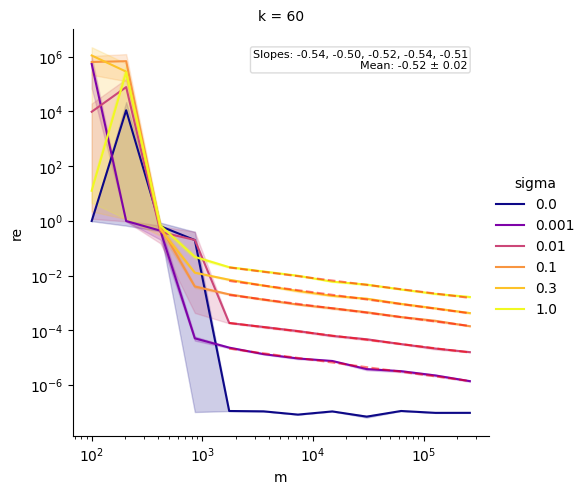

In [8]:
mydf = df[(df['adapted_sampling']==True)&(df['alg']=='bpdn_projected')]

fit_df = perform_least_squares_fit(
    mydf[mydf['sigma'] > 1e-4],
    x_col='m',
    y_col='re',
    group_cols=['k', 'sigma', 'alg', 'img', 'sampling_type', 'adapted_sampling'],
    min_x=10**3.2
)


# Create the main plot
g = sns.relplot(
    data=mydf,
    kind="line",
    x="m",
    y="re",
    col = 'k',
    palette="plasma",
    hue="sigma",
    hue_norm=LogNorm(vmin=1e-4, clip=True),
    errorbar="se"
)

g.set(xscale="log", yscale="log")

plot_on_facets(add_fit_lines_to_plot, g, fit_df, col_label="k", row_label="alg")

plt.show()


In [ ]:
df=df[df['m']> 10**(2.5)]
df=df[df['adapted_sampli']]

In [38]:
df['m'].unique()

array([   418,    856,   1750,   3580,   7322,  14977,  30635,  62660,
       128163, 262144])

In [55]:
df[df['m']== df['m'].unique()[0]][df['sigma']==0].shape

/var/folders/9d/dmf_3v3d5cg6drc619z979yc0000gn/T/ipykernel_26451/146882140.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df['m']== df['m'].unique()[0]][df['sigma']==0].shape


(5, 18)

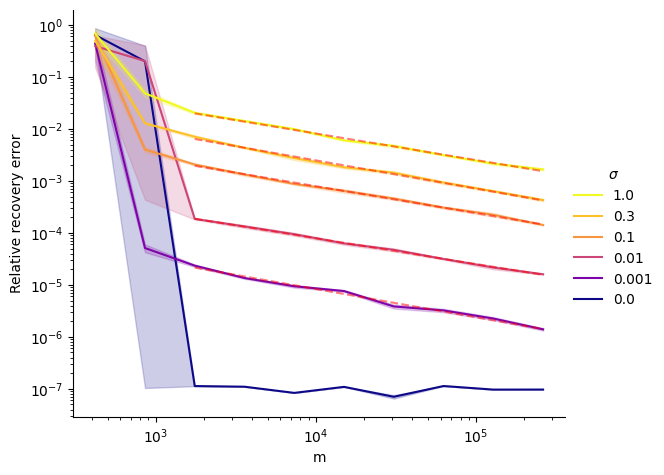

In [57]:
# df_wr = df[df['sampling_type']=='wr']
# mydf = df_wr[df_wr['adapted_sampling']==True]
# mydf = df_wr[mydf['img']=="phantom"]
# doubledf = melt_and_keep(df, ["re","emp_snr"])
# g = sns.relplot(doubledf, kind = "line", x = "m", y="value", row ="variable", col="k", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False}
%matplotlib inline
g = sns.relplot(df, kind = "line", x = "m", y="re", row="alg", col='k',  hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se")
# Get the current legend handles and labels from the FacetGrid's legend
handles = g.legend.get_lines()  # or get_patches() if the legend uses patches
labels = [t.get_text() for t in g.legend.get_texts()]

# Reverse the handles and labels
handles = handles[::-1]
labels = labels[::-1]

# Remove the existing legend
g.legend.remove()

# Add the reversed legend back
g.add_legend(handles=handles, labels=labels, title=r'$\sigma$', loc='center right')

fits = perform_least_squares_fit(df[df['sigma'] > 0], 'm', 're', 'sigma', 1000)
add_fit_lines_to_plot(fits, g.ax, annotate_slopes=False)
plt.ylabel("Relative recovery error")
plt.title("")
# for ax in g.axes.flat:
#     ax.set_yscale('log')  # Set y-axis to log scale
plt.yscale('log')  # Set y-axis to log scale
plt.xscale("log")
plt.savefig("sparse_recov.pdf")
#doubledf=melt_and_keep(mydf, ["re","unique_meas"])

In [11]:
melt_and_keep(df, ["re","emp_snr"]).columns

Index(['m', 'k', 'sigma', 'img', 'sampling_type', 'adapted_sampling',
       'preconditionned_optimization', 'alg', 'seed', 'runtime_seconds',
       'indices', 'experiment_fn_label', 'm_tld', 'noise_mag', 'signal_mag',
       'experiment_found', 'variable', 'value'],
      dtype='object')

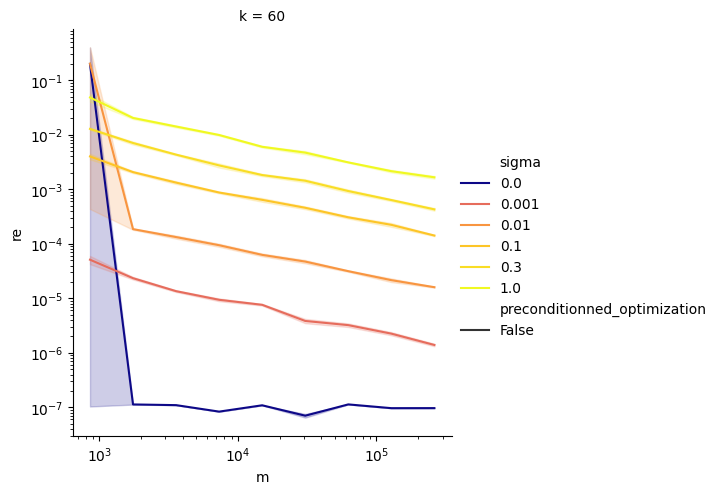

In [17]:
sns.relplot(df, kind = "line", x = "m", y="re", col="k", style="preconditionned_optimization", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se")
plt.xscale("log")
plt.yscale("log")

In [37]:
%matplotlib inline
g = sns.relplot(doubledf, kind = "line", x = "m", y="value", col="k", row="variable", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se", facet_kws={'sharey':False})
for ax in g.axes.flat:
    ax.set_yscale('log')  # Set y-axis to log scale
plt.xscale("log")

NameError: name 'doubledf' is not defined

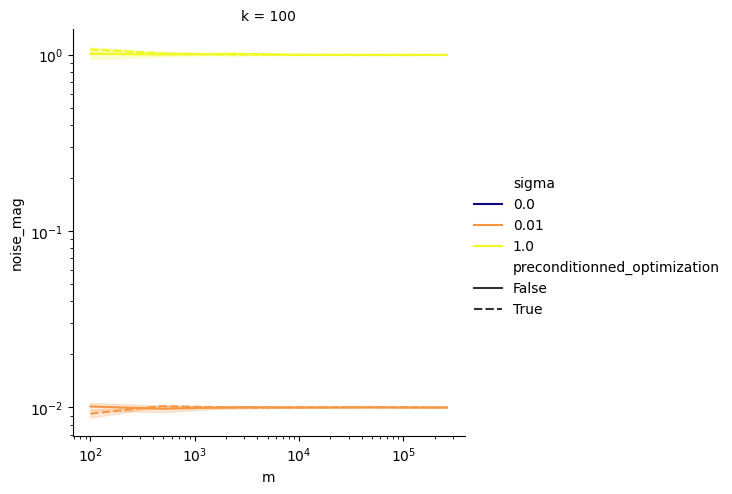

In [ ]:
sns.relplot(df, kind = "line", x = "m", y="noise_mag", col="k", style="preconditionned_optimization", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se")
plt.xscale('log')
plt.yscale('log')

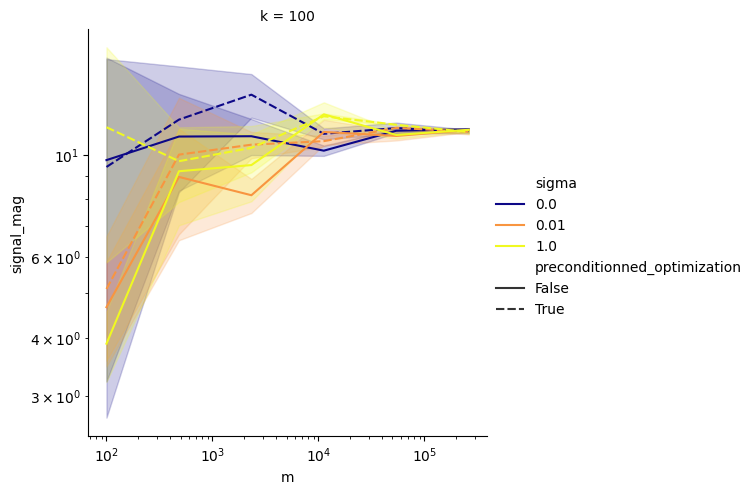

In [ ]:
sns.relplot(df, kind = "line", x = "m", y="signal_mag", col="k", style="preconditionned_optimization", hue="sigma", hue_norm=LogNorm(vmin=1e-8, clip=True) , palette="plasma", errorbar="se")
plt.xscale('log')
plt.yscale('log')

In [ ]:
kkjdf_wr

NameError: name 'kkjdf_wr' is not defined